In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
from jetset.template_2Dmodel import EBLAbsorptionTemplate
from tbabs_absorption_jetset import tbabsAbsorptionTemplate
from ebv_absorption_jetset import GalacticReddeningTemplate

from astropy.table import Table

In [ ]:
from jetset.plot_sedfit

## Built in EBL

In [3]:
ebl_finke=EBLAbsorptionTemplate.from_name('Finke_2010')

## tbabs Absorption
Using the files from the [github repository](https://github.com/mireianievas/gammapy_mwl_workflow) associated with the work "[Unified multiwavelength data analysis workflow with gammapy](https://doi.org/10.1051/0004-6361/202452349)" we construct the tbabs absorption model for jetset.

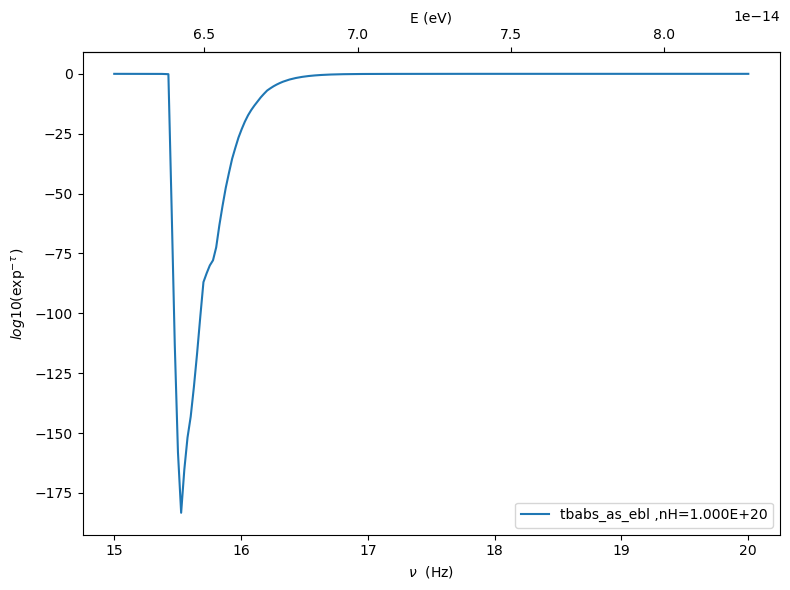

In [11]:
tbabsfile="/home/user/Documents/gammapy_mwl_workflow-main/Models/tbabs_tau_factor_vs_nH_energy.ecsv"
tbabs_table = Table.read(tbabsfile,format='ascii.ecsv')
tbabs_data  = tbabs_table.as_array()
tbabs_data  = tbabs_data.view(np.float64).reshape(tbabs_data.shape + (-1,))

log_nh_array_20 = np.asarray(tbabs_table.meta['log10_nH_values'])
nh_values=1e22*np.power(10.0,log_nh_array_20)
log_en_array    = np.asarray(tbabs_table.meta['log10_E_values'])#keV
energy=np.power(10.0,log_en_array)
frequency = (energy*u.keV).to(u.Hz,equivalencies=u.spectral())

tbabs=tbabsAbsorptionTemplate(hydrogen_column_density_array=nh_values,
                            energy_array=np.log10(frequency.value),
                            tau_array=tbabs_data.T,
                            applied_model=None, nH=1e20, template_name='tbabs_as_ebl', nu_size=100,)


tbabs.eval(nu=np.logspace(15,20,200))
tbabs.plot_model()

## Galactic Reddening
Using the files from the [github repository](https://github.com/mireianievas/gammapy_mwl_workflow) associated with the work "[Unified multiwavelength data analysis workflow with gammapy](https://doi.org/10.1051/0004-6361/202452349)" we construct the galactic reddening absorption model for jetset.

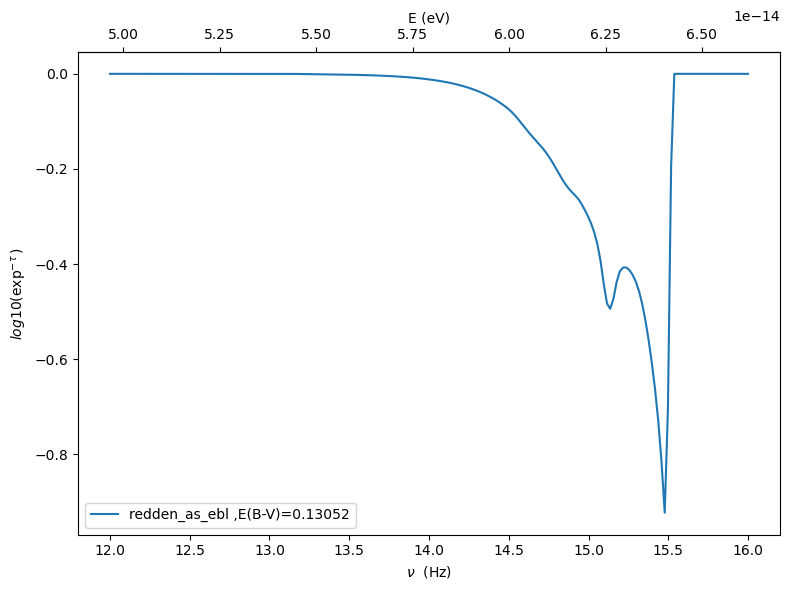

In [9]:
ebv_value=0.1

xreddenfile="/home/user/Documents//gammapy_mwl_workflow-main/Models/xredden_tau_factor_vs_EBV_energy.ecsv"
xredden_table = Table.read(xreddenfile,format='ascii.ecsv')
xredden_data = np.asarray([[k for k in j] for j in xredden_table])
xredden_data[xredden_data>1e5] = 1e5
ebv_array    = np.asarray(xredden_table.meta['ebv_values'])
log_en_array = np.asarray(xredden_table.meta['log10_E_values'])

energy = 10**log_en_array
frequency = (energy*u.eV).to(u.Hz,equivalencies=u.spectral())


redden2=GalacticReddeningTemplate(reddening_array=ebv_array,
                            energy_array=np.log10(frequency.value),
                            tau_array=xredden_data.T,
                            applied_model=None, ebv=ebv_array[np.sum(ebv_array<ebv_value)], template_name='redden_as_ebl', nu_size=100,)
                                    # energy_array=np.log10((ebl_1_52[0]*u.TeV).to(u.Hz,equivalencies=u.spectral()).value),
                                    # tau_array=np.array([ebl_1_52[1],ebl_1_53[1]]),
                                    # applied_model=None, z=1.522, template_name='tbabs', nu_size=100)

redden2.eval(nu=np.logspace(12,16,200))
redden2.plot_model()

## Using the absorption models
Here we demonstrate the use of these absorption models in a compoite jet model. The new absorption features are plainly visible.

In [12]:
from jetset.jet_model import Jet
basic_jet=Jet(electron_distribution='lppl',name='basic_jet')

===> setting C threads to 8


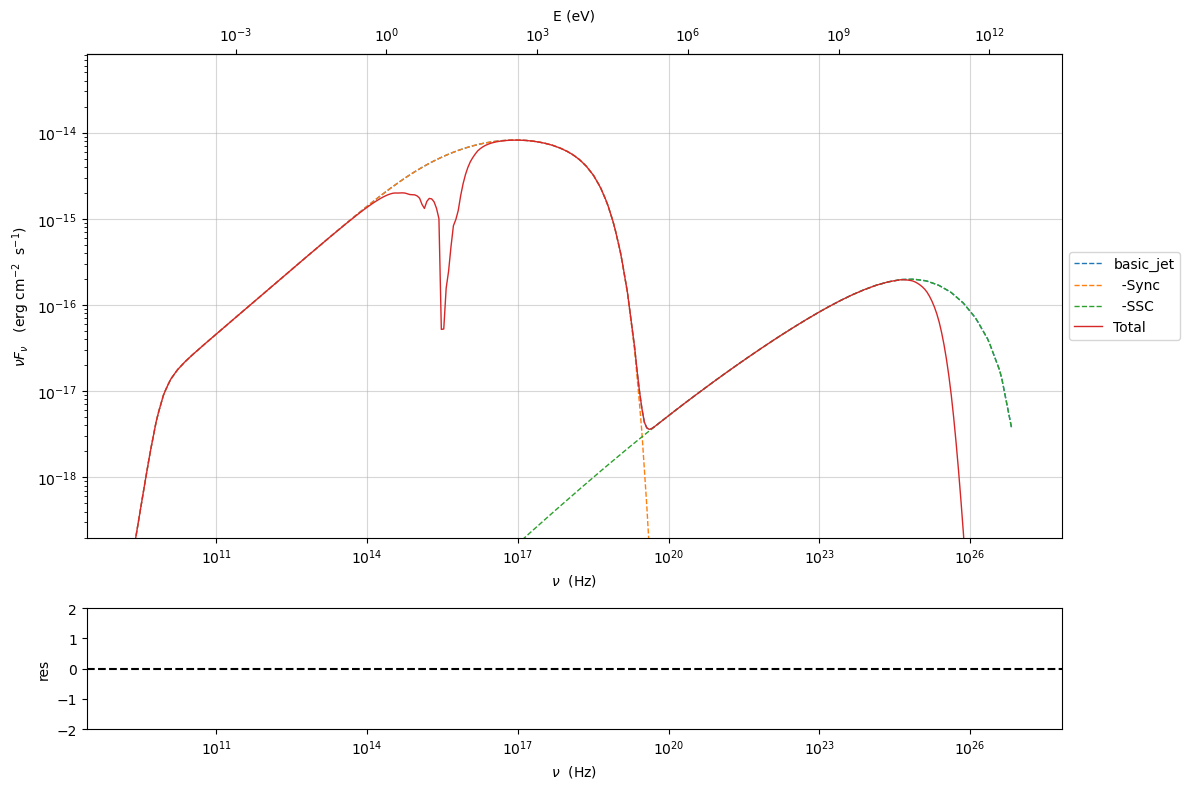

In [15]:
from jetset.model_manager import FitModel

jet_total = FitModel(nu_size=500, name="Total")
jet_total.add_component(basic_jet)
jet_total.add_component(redden2)
jet_total.add_component(ebl_finke)
jet_total.add_component(tbabs2)
# jet_total.composite_expr = (
#     "gal_redden_as_ebl*tbabs_as_ebl*finke_2022*(quiescent+host_galaxy+extended)"
# )
jet_total.composite_expr = (
    "redden_as_ebl*tbabs_as_ebl*Finke_2010*(basic_jet)"
)
jet_total.eval()
p=jet_total.plot_model()